# Lesson 2 · Time-Series Data Preparation
**Phase 7: Time-Series Analysis & Forecasting** &nbsp;|&nbsp; **Week 13** &nbsp;|&nbsp; ⏱ ≈ 100 minutes

> 🎯 **By the end of this lesson you will be able to:**
    > - Parse dates and build a clean **datetime index**
> - Detect and handle **duplicates, outliers and missing timestamps**
> - **Resample** between frequencies using the right aggregation
> - Compute **rolling and expanding statistics** without leaking the future
> - Generate **lag features** and **seasonal (calendar / Fourier) features**
> - Prove a feature pipeline is leak-free with the *future-poisoning test*

**Prerequisites:** Lessons 0–1; pandas basics.

**How to work through this notebook:** read a section, *predict* what the next cell will show, run it, and compare.
Prediction before execution is the fastest way to build intuition. Problems come with progressive hints (open them one at a time:
struggling a little is where learning happens). Reference solutions live in `solutions/`.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

## 0 · The story: why do data scientists spend 80 % of their time cleaning?

Our maize trader receives a spreadsheet from a market clerk. Open `data/maize_daily_raw.csv` in a text editor and you'll find
the usual horrors: duplicated rows, missing days, a price typed as `400.4` instead of `40.04`, and "n/a" typed into a numeric column.
A forecasting model trained on this will happily learn the typos. **Garbage in, garbage forecast.**

Today's pipeline:

```
raw CSV → parse dates → drop duplicates → datetime index → fix outliers
        → handle missing timestamps → resample → rolling/lag/seasonal features → model-ready table
```

## 1 · Datetime indexing

A **DatetimeIndex** turns pandas into a time-aware tool: slicing by date strings, resampling, shifting by time, and plotting with sensible axes all just work.

Three steps, *always in this order*: **parse → sort → set_index**.

In [2]:
raw = pd.read_csv(DATA / "maize_daily_raw.csv")
print(raw.dtypes, "\n")
raw.head()

date               str
price          float64
rainfall_mm    float64
dtype: object 



,date,price,rainfall_mm
0,2022-01-01,61.59,8.5
1,2022-01-03,61.00,0.0
2,2022-01-04,59.78,0.0
3,2022-01-05,59.91,0.0
4,2022-01-06,61.37,0.0


Notice `date` is a plain **string** (object). Strings sort alphabetically and can't do date arithmetic. Convert it:

In [3]:
df = raw.drop_duplicates().copy()                        # 1) duplicates (8 of them)
df["date"] = pd.to_datetime(df["date"])                  # 2) strings -> real timestamps
df = df.sort_values("date").set_index("date")            # 3) sort, then index by date
print(type(df.index).__name__, "| from", df.index.min().date(), "to", df.index.max().date())

# The superpowers of a DatetimeIndex:
print(df.loc["2023-06"].head(3))                         # partial-string slicing: all of June 2023
print(df.loc["2023-06-10":"2023-06-14"].index.day_name().tolist())  # date ranges + .day_name()

DatetimeIndex | from 2022-01-01 to 2024-12-31
            price  rainfall_mm
date                          
2023-06-01  42.34          0.0
2023-06-02  42.54          0.0
2023-06-03  43.58          0.0
['Saturday', 'Monday', 'Tuesday', 'Wednesday']


> ⚠️ **Parsing gotcha:** `"03/04/2023"` is 3 April in most of the world and 4 March in the US. When dates aren't ISO (`YYYY-MM-DD`),
> always pass an explicit `format="%d/%m/%Y"` (or `dayfirst=True`). Silent mis-parsing creates plausible-looking but wrong data.

## 2 · Missing timestamps (the *rows that aren't there*)

Missing **values** (`NaN`) are easy to spot. Missing **timestamps**: rows that were never recorded: are invisible until you look for them.
Most time-series algorithms **assume a regular grid**, so we must make the gaps explicit.

In [4]:
full_range = pd.date_range(df.index.min(), df.index.max(), freq="D")
missing_days = full_range.difference(df.index)
sundays = missing_days[missing_days.dayofweek == 6]
print(f"Calendar days: {len(full_range)} | present: {len(df)} | missing: {len(missing_days)}")
print(f"  of which Sundays (market closed): {len(sundays)}")
print(f"  other gaps (genuinely missing):   {len(missing_days) - len(sundays)}")

Calendar days: 1096 | present: 911 | missing: 185
  of which Sundays (market closed): 157
  other gaps (genuinely missing):   28


Two *very different* kinds of "missing":

| Kind | Example | Right treatment |
|---|---|---|
| **Structural** (the thing didn't exist) | Market closed on Sundays | Don't invent prices! Drop them or model as business days |
| **Accidental** (we failed to record it) | Clerk absent on a Tuesday | Impute carefully |

### Outliers first, imputation second
Typos must be turned into `NaN` *before* imputing, otherwise we'd propagate them. The robust trick: compare each value to a rolling **median**.

In [5]:
daily = df.copy()
med = daily["price"].rolling(7, center=True, min_periods=3).median()
ratio = daily["price"] / med
bad = (ratio > 2) | (ratio < 0.5)
print("Suspicious rows:\n", daily.loc[bad, "price"].to_frame().assign(rolling_median=med[bad].round(2)))

daily.loc[bad, "price"] = np.nan                  # turn typos into honest 'unknown'
print("\nMissing prices now:", daily["price"].isna().sum())

Suspicious rows:
              price  rolling_median
date                              
2022-07-12    4.42           43.01
2023-06-24  400.40           39.23
2023-12-13  495.10           50.20
2024-05-29  436.70           43.99
2024-06-14    4.32           42.62

Missing prices now: 10


### Imputation options: and which are safe for forecasting

| Method | How | Leaks the future? |
|---|---|---|
| **Forward fill** `ffill()` | repeat last known value | ✅ **No**: uses only the past |
| Linear / time interpolation | straight line between neighbours | ❌ **Yes**: uses the *next* known value |
| Backward fill `bfill()` | copy the next value backwards | ❌ **Yes** |
| Seasonal / model-based | e.g. same weekday last year | depends |

> 🧠 **Key rule:** for *exploration and historical clean-up*, interpolation is fine. Inside a **forecasting pipeline** (anything that feeds a model evaluated on a test set),
> prefer **forward-fill** or fit the imputer on the training window only.

Gaps to fill on the trading calendar: 38


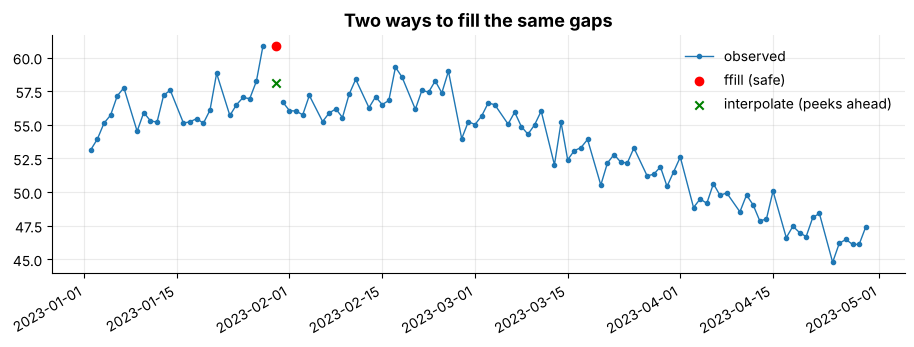

Remaining NaNs: 0


In [6]:
# Put the data on a regular business-day grid (Mon–Sat): Sundays vanish, accidental gaps become NaN
mkt_days = pd.offsets.CustomBusinessDay(weekmask="Mon Tue Wed Thu Fri Sat")
grid = pd.date_range(daily.index.min(), daily.index.max(), freq=mkt_days)
daily_grid = daily.reindex(grid)
print("Gaps to fill on the trading calendar:", daily_grid["price"].isna().sum())

filled_ffill = daily_grid["price"].ffill()
filled_interp = daily_grid["price"].interpolate(method="time")

gap_dates = daily_grid.index[daily_grid["price"].isna()]
ax = daily_grid.loc["2023-01":"2023-04", "price"].plot(marker=".", lw=1, label="observed", figsize=(11, 3.5))
g = gap_dates[(gap_dates >= "2023-01-01") & (gap_dates <= "2023-04-30")]
ax.scatter(g, filled_ffill.loc[g], color="red", zorder=5, label="ffill (safe)")
ax.scatter(g, filled_interp.loc[g], color="green", marker="x", zorder=5, label="interpolate (peeks ahead)")
ax.legend(); ax.set_title("Two ways to fill the same gaps"); plt.show()

daily_clean = daily_grid.copy()
daily_clean["price"] = filled_ffill
daily_clean["rainfall_mm"] = daily_clean["rainfall_mm"].fillna(0)      # a missing rain record: assume none
print("Remaining NaNs:", int(daily_clean.isna().sum().sum()))

## 3 · Resampling & frequency conversion

**Resampling** changes the sampling frequency:
- **Downsampling** (daily → weekly → monthly): *aggregate*: you must choose *how* (mean? sum? last?).
- **Upsampling** (monthly → weekly): *invent* in-between values: you must choose a fill rule.

`.resample(rule).agg(...)` is a *groupby over time buckets*. Common rules: `"D"` day, `"W-SUN"` weeks ending Sunday, `"MS"`/`"ME"` month start/end, `"QE"` quarter end, `"YE"` year end.

> ℹ️ pandas ≥ 2.2 uses `"ME"`, `"QE"`, `"YE"` for *end*-anchored offsets. Older tutorials use `"M"`, `"Q"`, `"Y"`: these are deprecated/removed.

daily: 939 | weekly: 158 | monthly: 36


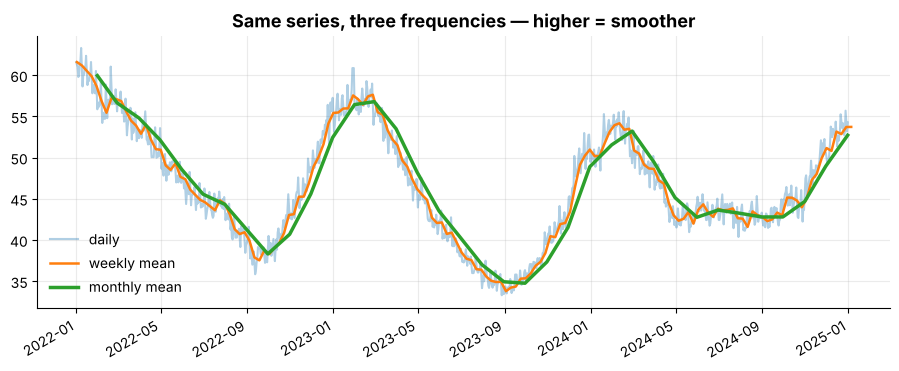

In [7]:
weekly = daily_clean.resample("W-SUN").agg({"price": "mean", "rainfall_mm": "sum"})     # level -> mean, flow -> sum
monthly = daily_clean.resample("ME").agg({"price": "mean", "rainfall_mm": "sum"})
print("daily:", len(daily_clean), "| weekly:", len(weekly), "| monthly:", len(monthly))

fig, ax = plt.subplots()
daily_clean["price"].plot(ax=ax, alpha=.35, label="daily")
weekly["price"].plot(ax=ax, label="weekly mean", lw=1.8)
monthly["price"].plot(ax=ax, label="monthly mean", lw=2.5)
ax.legend(); ax.set_title("Same series, three frequencies; higher = smoother"); ax.set_xlabel(""); plt.show()

### `asfreq` vs `resample`: a classic mix-up
- `s.asfreq("W-SUN")` **picks** the value at each new timestamp (no aggregation; creates `NaN` where there's no exact match).
- `s.resample("W-SUN").mean()` **aggregates** all observations within each bucket.

**Upsampling** (e.g., a monthly price used on a weekly model):

In [8]:
up = monthly["price"].resample("W-SUN").ffill()        # each week inherits its month's value
print(up.head(6).round(2))

2022-02-06    59.95
2022-02-13    59.95
2022-02-20    59.95
2022-02-27    59.95
2022-03-06    56.64
2022-03-13    56.64
Freq: W-SUN, Name: price, dtype: float64


## 4 · Rolling & expanding statistics

A **rolling window** summarises the most recent *w* observations: moving average, rolling volatility, rolling min/max.
They reveal local trend and risk and make excellent features.
**Expanding** windows grow from the first observation to *now* (cumulative statistics). **EWM** (exponentially weighted) gives recent points more weight.

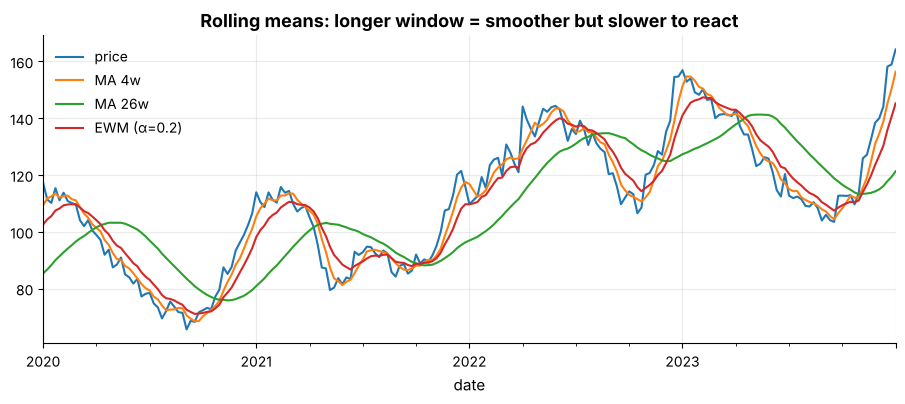

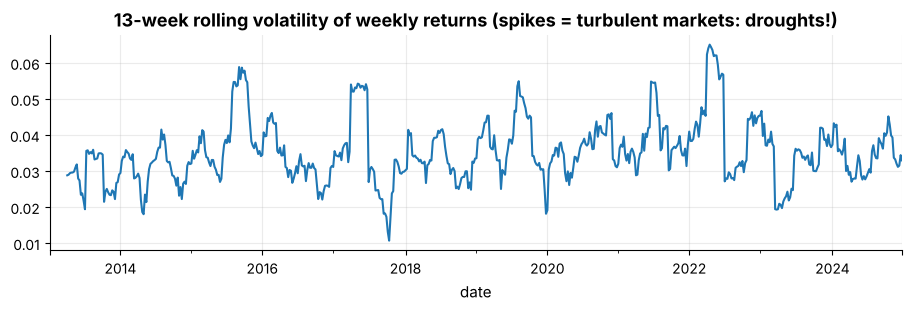

In [9]:
mz = load_weekly("maize")["price"]
roll = pd.DataFrame({
    "price": mz,
    "MA 4w": mz.rolling(4).mean(),
    "MA 26w": mz.rolling(26).mean(),
    "EWM (α=0.2)": mz.ewm(alpha=0.2).mean(),
})
roll.loc["2020":"2023"].plot(figsize=(11, 4), title="Rolling means: longer window = smoother but slower to react"); plt.show()

vol = np.log(mz).diff().rolling(13).std()
vol.plot(figsize=(11, 2.8), title="13-week rolling volatility of weekly returns (spikes = turbulent markets: droughts!)"); plt.show()

> ⚠️ **The centred-window trap.** `rolling(5, center=True)` averages 2 weeks *before* and 2 weeks *after* the date. It's a lovely smoother for charts but **peeks into the future**.
> For model features use the default **trailing** window, and `.shift(1)` so today's own value isn't included in the feature for predicting today.

## 5 · Lag features: turning a time series into a table

Machine-learning models (Linear Regression, Random Forest, XGBoost…) expect a table `X → y`.
A time series has no obvious `X`, so we **manufacture** it from the past:

| row (time t) | `lag_1` | `lag_2` | `lag_4` | `roll4` | target `y_t` |
|---|---|---|---|---|---|
| week 10 | y₉ | y₈ | y₆ | mean(y₆..y₉) | y₁₀ |

Everything on the left is known *before* week 10 happens; the target is what we want to predict.

In [10]:
s = mz.copy()
feat = pd.DataFrame({
    "y":      s,
    "lag_1":  s.shift(1),
    "lag_2":  s.shift(2),
    "lag_4":  s.shift(4),
    "lag_52": s.shift(52),
    "roll4":  s.shift(1).rolling(4).mean(),       # shift(1) BEFORE rolling => window excludes today
})
feat.iloc[50:56].round(2)

,y,lag_1,lag_2,lag_4,lag_52,roll4
date,,,,,,
2013-12-22,61.29,60.95,56.58,53.10,NaN,56.46
2013-12-29,59.94,61.29,60.95,55.22,NaN,58.51
2014-01-05,58.62,59.94,61.29,56.58,55.39,59.69
2014-01-12,56.69,58.62,59.94,60.95,55.35,60.20
2014-01-19,60.02,56.69,58.62,61.29,55.29,59.14
2014-01-26,62.07,60.02,56.69,59.94,56.81,58.82


Notice the first rows are `NaN` (nothing exists 52 weeks before week 1). We **drop** them with `.dropna()`: never fill them with zeros (that tells the model "the price was 0 last year").

**Exogenous lags** (rainfall, fuel) work identically. Rain affects maize prices about 8 weeks later (a planted-crop delay!), so `rainfall_mm.shift(8)` is a useful feature.

### 🕵️ Detect leakage automatically: the *future-poisoning test*
Replace everything after some date with garbage and recompute the features. If **earlier rows change**, a feature was peeking ahead.
We built `leakage_check` for this; you'll use it a lot.

In [11]:
safe = lambda s: pd.DataFrame({"lag_1": s.shift(1), "roll4": s.shift(1).rolling(4).mean()})
leaky = lambda s: pd.DataFrame({"lag_1": s.shift(1), "roll4": s.rolling(4, center=True).mean()})   # <- centred!
print("safe pipeline:");  leakage_check(safe, mz)
print("leaky pipeline:"); leakage_check(leaky, mz)

safe pipeline:
✅ No leakage detected: past rows never changed when the future was poisoned.
leaky pipeline:
🚨 LEAKAGE: rows before the 50% cut changed. Culprit column(s): ['roll4']


False

## 6 · Seasonal features

Tree and linear models don't know that week 52 and week 1 are neighbours. We hand them the calendar in a smart form:

| Feature | Idea | Notes |
|---|---|---|
| `month`, `week_of_year`, `day_of_week` | integer category | trees handle these natively; linear models need one-hot |
| **Cyclical encoding** `sin(2πk·doy/365.25)`, `cos(…)` | maps the calendar onto a circle | December is *close* to January: integers say they're 11 apart |
| **Fourier terms** (k = 1, 2, 3 …) | several harmonics = flexible seasonal shape | the standard trick for long periods (weekly → period 52) |
| Holiday / event flags | `festival_flag` | calendar-known in advance → no leakage |
| Time index `t` | 0, 1, 2, … | lets linear models capture trend |

Calendar features are **deterministic**: you know the date of next week's forecast already, so including them never leaks.

In [12]:
cal = calendar_features(mz.index, fourier_k=2)
cal.head(3).round(3)

,month,week_of_year,sin1,cos1,sin2,cos2
date,,,,,,
2013-01-06,1,1,0.103,0.995,0.205,0.979
2013-01-13,1,2,0.222,0.975,0.432,0.902
2013-01-20,1,3,0.337,0.941,0.635,0.772


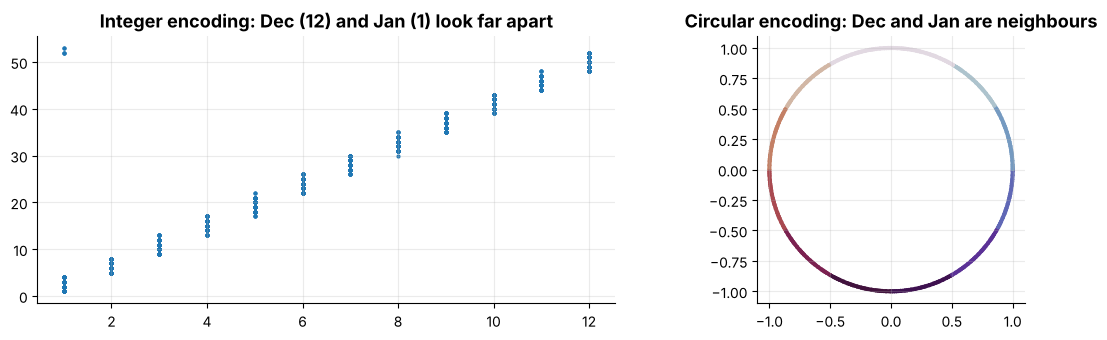

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].scatter(cal["month"], cal["week_of_year"], s=4); ax[0].set_title("Integer encoding: Dec (12) and Jan (1) look far apart")
ax[1].scatter(cal["sin1"], cal["cos1"], s=4, c=cal["month"], cmap="twilight"); ax[1].set_title("Circular encoding: Dec and Jan are neighbours")
ax[1].set_aspect("equal"); plt.tight_layout(); plt.show()

## 7 · Putting it all together: `make_features`

`course_utils.make_features` wraps everything (lags, trailing rolling stats, exogenous lags, calendar features) with built-in safeguards
(it *refuses* a lag shorter than the forecast horizon `h`). We will use it from Lesson 6 on.

In [14]:
tomato = load_weekly("tomato")
X, y = make_features(tomato, target="price", lags=(1, 2, 4, 52), windows=(4, 12),
                     exog=("rainfall_mm", "fuel_index"), exog_lags=(4, 8), h=1)
data = X.join(y).dropna()
print(f"{X.shape[1]} features; {len(data)} usable rows out of {len(tomato)} (52 lost to the lag_52 warm-up)")
print(list(X.columns))
leakage_check(lambda s: make_features(s.to_frame("price"), lags=(1, 2, 4, 52), windows=(4, 12))[0], tomato["price"])

18 features; 574 usable rows out of 626 (52 lost to the lag_52 warm-up)
['price_lag_1', 'price_lag_2', 'price_lag_4', 'price_lag_52', 'price_rollmean_4', 'price_rollstd_4', 'price_rollmean_12', 'price_rollstd_12', 'rainfall_mm_lag_4', 'rainfall_mm_lag_8', 'fuel_index_lag_4', 'fuel_index_lag_8', 'month', 'week_of_year', 'sin1', 'cos1', 'sin2', 'cos2']


✅ No leakage detected: past rows never changed when the future was poisoned.


True

## 🧩 Practice problems
Problems 2.1–2.3 use the worked-example variables (`df`, `daily`, `daily_clean`). Run the notebook top-to-bottom first.

### 🧩 Problem 2.1 · Triage the raw file  ·  🟢 Easy

Load `data/maize_daily_raw.csv` into `raw`. Then answer: (a) how many rows does it have, (b) how many are **exact duplicate rows**,
  (c) how many prices are missing? Finally, drop the duplicates and store the remaining row count in `n_clean`.

<details><summary>💡 Hint 1</summary>

`pd.read_csv(DATA / 'maize_daily_raw.csv')`: `DATA` is already defined for you by `course_utils`.

</details>

<details><summary>💡 Hint 2</summary>

`raw.duplicated().sum()` counts duplicate rows; `raw['price'].isna().sum()` counts missing prices.

</details>

<details><summary>💡 Hint 3</summary>

`raw.drop_duplicates()` removes duplicates (keeps the first occurrence).

</details>

In [15]:
raw = pd.read_csv(DATA / 'maize_daily_raw.csv')
n_clean = None
# YOUR CODE HERE
check('rows after removing duplicates', n_clean, 911)

⏳ rows after removing duplicates: not answered yet (replace the `None` with your answer)


### 🧩 Problem 2.2 · Catch the decimal-point typos  ·  🟡 Medium

Starting from the de-duplicated, date-indexed DataFrame `df` in the worked example (before any outlier treatment), find the **data-entry outliers** (prices that are ~10× too big or ~10× too small).
  Use the **ratio of each price to its centred 7-day rolling median**; flag ratios above 2 or below 0.5. Store the number found in `n_outliers`,
  and set those prices to `NaN`.

<details><summary>💡 Hint 1</summary>

`med = df['price'].rolling(7, center=True, min_periods=3).median()`: the median is robust: one crazy value barely moves it.

</details>

<details><summary>💡 Hint 2</summary>

`ratio = df['price'] / med`, then `mask = (ratio > 2) | (ratio < 0.5)`.

</details>

<details><summary>💡 Hint 3</summary>

`daily_fixed.loc[mask, 'price'] = np.nan`: and `mask.sum()` is your count.

</details>

In [16]:
daily_fixed = df.copy()
n_outliers = None
# YOUR CODE HERE
check('outliers found', n_outliers, 5)

⏳ outliers found: not answered yet (replace the `None` with your answer)


### 🧩 Problem 2.3 · Weekly vs monthly aggregation  ·  🟡 Medium

Using `daily_clean` (price + rainfall, daily index) from the worked example, resample to **monthly** (`'ME'`) taking the **mean price** and the **total rainfall**.
  Which month was the wettest, and how many millimetres fell?

<details><summary>💡 Hint 1</summary>

`resample('ME')` groups by month-end. Use `.agg({'price': 'mean', 'rainfall_mm': 'sum'})`.

</details>

<details><summary>💡 Hint 2</summary>

Rainfall is a *flow* (amount per period) so we **sum** it; a price is a *level* so we average it (or take the last value).

</details>

<details><summary>💡 Hint 3</summary>

`monthly['rainfall_mm'].idxmax()` returns the wettest month.

</details>

In [17]:
# YOUR CODE HERE

### 🧩 Problem 2.4 · Build your own lag features  ·  🟡 Medium

For the weekly **tomato** price build a DataFrame `feat` with these columns, **without** using `make_features`:
  `lag_1`, `lag_4`, `lag_52` (price shifted), `roll4` (mean of the previous 4 weeks), and `rain_lag_8` (rainfall 8 weeks ago).
  Then run `leakage_check` to prove it is leak-free.

<details><summary>💡 Hint 1</summary>

`s.shift(1)` is last week's price: the value k steps in the past is `s.shift(k)`.

</details>

<details><summary>💡 Hint 2</summary>

For a rolling mean of the *previous* 4 weeks (not including today): `s.shift(1).rolling(4).mean()`.

</details>

<details><summary>💡 Hint 3</summary>

Wrap everything in a function `f(s)` of the price series only (rain can be passed from `tomato['rainfall_mm']`), then call `leakage_check(f, s)`.

</details>

In [18]:
tomato = load_weekly('tomato')
s = tomato['price']
# YOUR CODE HERE

### 🧩 Problem 2.5 · The leakage detective  ·  🔴 Challenge

The function `buggy_features` below contains **three different leakage bugs**. Use `leakage_check` to confirm the leak, find the culprit columns,
  then write `fixed_features` that preserves the *idea* of each column but removes the leak.

<details><summary>💡 Hint 1</summary>

Run `leakage_check(buggy_features, s)`: it names the guilty columns.

</details>

<details><summary>💡 Hint 2</summary>

Bug types: (1) a centred rolling window, (2) a negative shift, (3) standardising with the *global* mean/std of the whole series.

</details>

<details><summary>💡 Hint 3</summary>

Fixes: (1) a trailing window on shifted data, (2) a *positive* shift, (3) an **expanding** mean/std (`s.expanding().mean()`), which at each time uses only the past.

</details>

In [19]:
s = load_weekly('maize')['price']
def buggy_features(s):
    return pd.DataFrame({
        'smooth':  s.rolling(5, center=True).mean(),
        'next_wk': s.shift(-1),
        'zscore':  (s - s.mean()) / s.std(),
    })
leakage_check(buggy_features, s)
# YOUR CODE HERE: def fixed_features(s): ...

🚨 LEAKAGE: rows before the 50% cut changed. Culprit column(s): ['smooth', 'next_wk', 'zscore']


False

## ✅ Recap checklist
- [ ] Parse → sort → index (and beware ambiguous date formats).
- [ ] Count duplicates / NaNs / gaps before fixing anything; separate **structural** from **accidental** missing.
- [ ] Fix outliers with robust tools (rolling **median**), *then* impute.
- [ ] Resample with the right aggregator: **sum** flows, **mean/last** levels.
- [ ] Rolling window for features = **trailing + shifted**; never `center=True`.
- [ ] Lag features via `shift`; never fill warm-up NaNs with zeros: drop them.
- [ ] Encode the calendar cyclically (sin/cos or Fourier).
- [ ] Run `leakage_check` on every feature pipeline.

### ⚠️ Common mistakes
1. Interpolating or back-filling **before** splitting train/test (the test period leaks into training).
2. Standardising with the mean/std of the **whole** dataset (fit scalers on the training window only).
3. Resampling with `mean()` on rainfall or sales volumes.
4. Treating a closed-market day as "missing" and interpolating invented prices.

### 🔮 Next lesson
We have clean, feature-rich data. How do we judge a forecast? **Lesson 3** introduces MAE, RMSE, MAPE (and its dangers), baselines, and the walk-forward validation that keeps us honest.